# Анализ продаж и качества доставки Olist

## Цель исследования

Оценить динамику заказов, средний чек и качество доставки
маркетплейса Olist, выявить возможные проблемы и
предложить рекомендации для бизнеса.

## Основные вопросы

1. Как меняется количество заказов и средний чек?
2. Насколько своевременно доставляются заказы?
3. Зависит ли качество доставки от стоимости заказа?
4. Связана ли нагрузка на маркетплейс с задержками?


**Данные:** Olist (таблицы заказов и товарных позиций). Основные KPI рассчитаны для доставленных заказов с известной датой доставки. Стоимость товаров приведена без расходов на доставку.

In [56]:
import pandas as pd
import matplotlib.pyplot as plt

In [57]:
from pathlib import Path

Path("images").mkdir(exist_ok=True)

In [58]:
order_items = pd.read_csv('data/olist_order_items_dataset.csv')
orders = pd.read_csv('data/olist_orders_dataset.csv')

In [59]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [60]:
orders.shape

(99441, 8)

In [61]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [62]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [63]:
order_items.shape

(112650, 7)

In [64]:
order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [65]:
orders.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [66]:
order_items.isna().sum()

,0
order_id,0
order_item_id,0
product_id,0
seller_id,0
shipping_limit_date,0
price,0
freight_value,0


In [67]:
orders.duplicated().sum()

np.int64(0)

In [68]:
order_items.duplicated().sum()

np.int64(0)

In [69]:
orders['order_status'].value_counts()

,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [70]:
# Проверка уникальности заказов
assert orders['order_id'].is_unique, "Есть повторяющиеся ID заказов"

# Проверка пропусков в идентификаторах
assert orders['order_id'].notna().all()
assert order_items['order_id'].notna().all()

# Проверка связности таблиц
assert order_items['order_id'].isin(orders['order_id']).all(), \
    "Есть товарные позиции без соответствующих заказов"

# Проверка стоимости товаров и доставки
assert order_items[['price', 'freight_value']].notna().all().all()
assert (order_items[['price', 'freight_value']] >= 0).all().all()

print("Все проверки данных пройдены!")


Все проверки данных пройдены!


In [71]:
order_items.describe()

,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


## 1ый промежуточный вывод после первичного анализа:

Таблица orders содержит даты соответствующие перемещению посылок, 99441 строк и 8 столбцов

Таблица order_items содержит 112650 строк и 7 столбцов и описание каждого товара

Таблица orders содержит пропущенные значения, дубикатов ни в одной из таблиц нет.

Большинство заказов имеют статус delivered — 96 478 заказов.

В таблице orders каждое значение order_id уникально. В таблице order_items существуют повторяющиеся значения order_id, так как один заказ может содержать несколько товаров.


**Перевод данных в дату и проверка**

In [72]:
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_approved_at'] = pd.to_datetime(orders['order_approved_at'])
orders['order_delivered_carrier_date'] = pd.to_datetime(orders['order_delivered_carrier_date'])
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])
orders['order_estimated_delivery_date'] = pd.to_datetime(orders['order_estimated_delivery_date'])

In [73]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  object        
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99281 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97658 non-null  datetime64[ns]
 6   order_delivered_customer_date  96476 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
dtypes: datetime64[ns](5), object(3)
memory usage: 6.1+ MB


In [74]:
order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'])

In [75]:
order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   order_id             112650 non-null  object        
 1   order_item_id        112650 non-null  int64         
 2   product_id           112650 non-null  object        
 3   seller_id            112650 non-null  object        
 4   shipping_limit_date  112650 non-null  datetime64[ns]
 5   price                112650 non-null  float64       
 6   freight_value        112650 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(3)
memory usage: 6.0+ MB


**Статусы заказов для которых в колонке "Дата доставки прокупателю" пропущенное значение.**

In [76]:
orders[orders['order_delivered_customer_date'].isna()]['order_status']

,order_status
6,invoiced
44,shipped
103,invoiced
128,processing
154,shipped
...,...
99283,canceled
99313,processing
99347,canceled
99348,unavailable


**Количество разных статусов заказов для которых в колонке "Дата доставки прокупателю" пропущенное значение.**

In [77]:
orders[orders['order_delivered_customer_date'].isna()]['order_status'].value_counts()

,count
order_status,
shipped,1107
canceled,619
unavailable,609
invoiced,314
processing,301
delivered,8
created,5
approved,2


**Количество доставленных заказов для которых неизвестна дата доставки покупателю**

Среди доставленных заказов обнаружено 8 записей без фактической даты доставки. Для анализа сроков доставки такие строки нужно исключить, так как для них невозможно рассчитать длительность доставки.

In [78]:
orders[orders['order_status'] == 'delivered']['order_delivered_customer_date'].isna().sum()

np.int64(8)

In [79]:
orders['order_purchase_timestamp'].min()

Timestamp('2016-09-04 21:15:19')

In [80]:
orders['order_purchase_timestamp'].max()

Timestamp('2018-10-17 17:30:18')

**Количество заказов за каждый год**

In [81]:
orders['order_purchase_timestamp'].dt.year.value_counts().sort_index()

,count
order_purchase_timestamp,
2016,329
2017,45101
2018,54011


In [82]:
delivered_orders = orders[orders['order_status'] == 'delivered']

In [83]:
delivered_orders.shape

(96478, 8)

In [84]:
delivered_orders = delivered_orders.dropna(subset = ['order_delivered_customer_date'])

In [85]:
delivered_orders.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,14
order_delivered_carrier_date,1
order_delivered_customer_date,0
order_estimated_delivery_date,0


In [86]:
sales = pd.merge(delivered_orders, order_items, on = 'order_id')

In [87]:
# Агрегируем товарные позиции по заказам
order_totals = (order_items.groupby("order_id", as_index=False).agg(product_value=("price", "sum"), freight_value=("freight_value", "sum")))
# Объединяем с доставленными заказами
order_metrics = delivered_orders.merge(
    order_totals,
    on="order_id",
    how="left",
    validate="one_to_one"
)
# Проверяем корректность объединения
assert len(order_metrics) == len(delivered_orders)
assert order_metrics["order_id"].is_unique
assert order_metrics["product_value"].notna().all()

print("Объединение выполнено")
print("Количество заказов:", len(order_metrics))
# Месяц заказа создаём один раз для всех графиков
order_metrics['month'] = order_metrics['order_purchase_timestamp'].dt.to_period('M')


Объединение выполнено
Количество заказов: 96470


In [88]:

# Проверяем наличие дат
date_cols = [
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

assert order_metrics[date_cols].notna().all().all()

# Фактический срок доставки в днях
order_metrics['delivery_days'] = (
    order_metrics['order_delivered_customer_date']
    - order_metrics['order_purchase_timestamp']
).dt.total_seconds() / 86400

# Проверяем отсутствие отрицательных сроков
assert (order_metrics['delivery_days'] >= 0).all()

# Проверяем опоздание по календарной дате
order_metrics['is_late'] = (
    order_metrics['order_delivered_customer_date'].dt.normalize()
    >
    order_metrics['order_estimated_delivery_date'].dt.normalize()
)

# Количество дней опоздания
order_metrics['delay_days'] = (
    order_metrics['order_delivered_customer_date'].dt.normalize()
    - order_metrics['order_estimated_delivery_date'].dt.normalize()
).dt.days.clip(lower=0)

print('Проверки дат пройдены')
display(order_metrics[
    ['delivery_days', 'is_late', 'delay_days']
].head())


Проверки дат пройдены


,delivery_days,is_late,delay_days
0,8.436574,False,0
1,13.782037,False,0
2,9.394213,False,0
3,13.208750,False,0
4,2.873877,False,0


In [89]:
print("Количество заказов:", len(order_metrics))
print("Стоимость товаров:", round(order_metrics["product_value"].sum(), 2))
print("Средний чек:", round(order_metrics["product_value"].mean(), 2))
print("Средний срок доставки:", round(order_metrics["delivery_days"].mean(), 2))
print("Доля задержек:", round(order_metrics["is_late"].mean() * 100, 2), "%")
print("P90 доставки:", round(order_metrics["delivery_days"].quantile(0.9), 2))


Количество заказов: 96470
Стоимость товаров: 13220248.93
Средний чек: 137.04
Средний срок доставки: 12.56
Доля задержек: 6.77 %
P90 доставки: 23.1


После объединения таблиц получено 110 189 товарных позиций, относящихся к 96 470 уникальным заказам.

**Стоимость товара в доставкой**

In [90]:
sales['total_item_value'] = sales['price'] + sales['freight_value']

**Общая стоимость проданных товаров**

In [91]:
sales['price'].sum()

np.float64(13220248.93)

**Общая сумма доставки**

In [92]:
sales['freight_value'].sum()

np.float64(2198145.9)

**Общая сумма выручки и доставки**

In [93]:
sales['total_item_value'].sum()

np.float64(15418394.83)

**Расчет общей стоимости каждого заказа**

In [94]:
order_summary = order_metrics.set_index('order_id')['product_value']
order_summary.describe()

,product_value
count,96470.000000
mean,137.040001
std,209.052608
min,0.850000
25%,45.900000
50%,86.500000
75%,149.900000
max,13440.000000


**Статистика стоимости заказа**

Средний чек выше медианного, что говорит о наличии дорогих заказов, которые увеличивают среднее значение. Стоимость большинства заказов ниже среднего чека

## Динамика продаж по месяцам

Для анализа динамики продаж данные сгруппированы по месяцу оформления заказа.

In [95]:
sales['month_of_order'] = sales['order_purchase_timestamp'].dt.to_period('M')

**Количество уникальных заказов по каждому месяцу**

In [96]:
monthly_orders = sales.groupby('month_of_order')['order_id'].nunique()
monthly_orders

,order_id
month_of_order,
2016-09,1
2016-10,265
2016-12,1
2017-01,750
2017-02,1653
2017-03,2546
2017-04,2303
2017-05,3545
2017-06,3135


**Стоимость проданных товаров по месяцам**

In [97]:
monthly_sales = sales.groupby('month_of_order')['price'].sum()
monthly_sales

,price
month_of_order,
2016-09,134.97
2016-10,40325.11
2016-12,10.90
2017-01,111798.36
2017-02,234223.40
2017-03,359198.85
2017-04,340669.68
2017-05,489159.25
2017-06,421923.37


**Средний чек по месяцам**

In [98]:
monthly_avg_check = monthly_sales / monthly_orders
monthly_avg_check

,0
month_of_order,
2016-09,134.970000
2016-10,152.170226
2016-12,10.900000
2017-01,149.064480
2017-02,141.695947
2017-03,141.083602
2017-04,147.924307
2017-05,137.985684
2017-06,134.584807


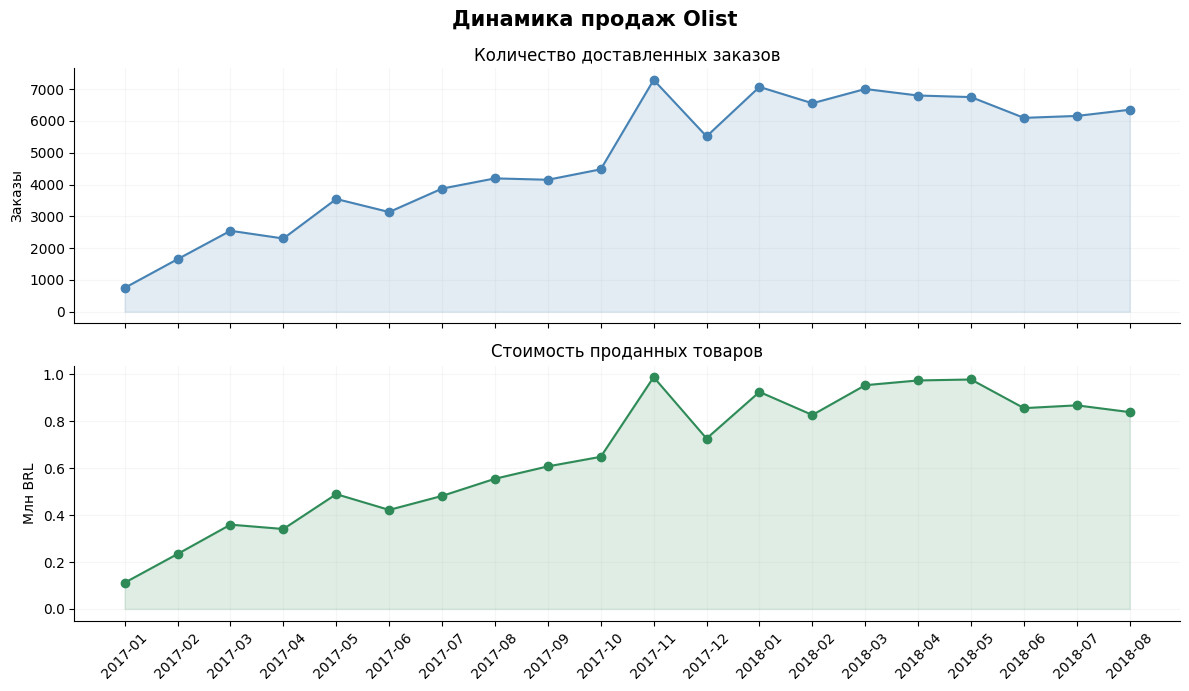

In [99]:

monthly_orders = monthly_orders[monthly_orders.index >= '2017-01']
monthly_sales = monthly_sales[monthly_sales.index >= '2017-01']

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(monthly_orders.index.astype(str), monthly_orders, marker='o', color='steelblue')
axes[0].fill_between(range(len(monthly_orders)), monthly_orders, alpha=0.15, color='steelblue')
axes[0].set_title('Количество доставленных заказов')
axes[0].set_ylabel('Заказы')

axes[1].plot(monthly_sales.index.astype(str), monthly_sales / 1e6, marker='o', color='seagreen')
axes[1].fill_between(range(len(monthly_sales)), monthly_sales / 1e6, alpha=0.15, color='seagreen')
axes[1].set_title('Стоимость проданных товаров')
axes[1].set_ylabel('Млн BRL')

for ax in axes:
    ax.grid(alpha=0.1)
    ax.spines[['top', 'right']].set_visible(False)

plt.xticks(rotation=45)
plt.suptitle('Динамика продаж Olist', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('images/sales_dynamics.png', dpi=200, bbox_inches='tight')

plt.show()

### Вывод

Данные за 2016 год представлены лишь частично, поэтому основная динамика оценивается начиная с 2017 года.

Анализ показал, что количество доставленных заказов и общая стоимость товаров имеют схожую динамику. В течение 2017 года оба показателя в целом увеличивались, а наиболее заметный рост наблюдался в ноябре.

В 2018 году количество заказов и стоимость товаров оставались относительно стабильными, несмотря на небольшие колебания. Таким образом, динамика стоимости товаров в значительной степени связана с изменением количества заказов.


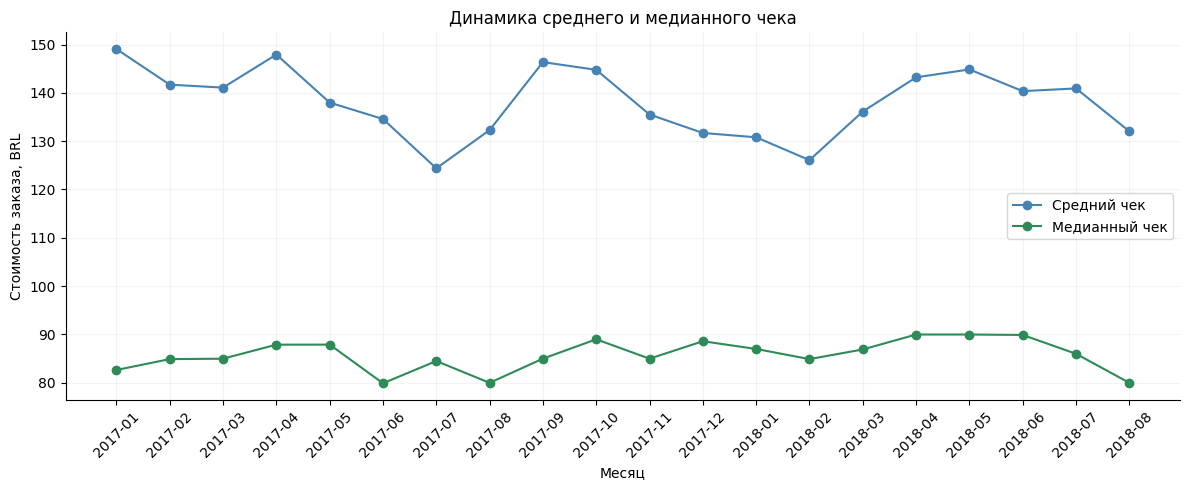

In [100]:
monthly_check = (order_metrics.groupby('month')['product_value'].agg(['mean', 'median']))
monthly_check = monthly_check[monthly_check.index >= '2017-01']

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_check.index.astype(str),monthly_check['mean'],marker='o',label='Средний чек',color='steelblue')
ax.plot(monthly_check.index.astype(str),monthly_check['median'],marker='o',label='Медианный чек',color='seagreen')
ax.set_title('Динамика среднего и медианного чека')
ax.set_xlabel('Месяц')
ax.set_ylabel('Стоимость заказа, BRL')
ax.legend()
ax.grid(alpha=0.15)
ax.spines[['top', 'right']].set_visible(False)

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('images/average_check.png', dpi=200, bbox_inches='tight')
plt.show()

### Вывод

Анализ показал, что в 2017–2018 годах средний чек оставался относительно стабильным и в основном находился в диапазоне 125–150 BRL. При этом медианный чек был заметно ниже — около 80–90 BRL.

Такая разница говорит о том, что более дорогие заказы повышают среднее значение, тогда как стоимость большинства типичных заказов значительно ниже.

Таким образом, для более полной оценки стоимости заказов важно учитывать не только средний, но и медианный чек, поскольку среднее значение может искажаться из-за небольшого количества дорогих покупок.

## Оценка качества доставки

In [101]:
order_metrics['delivery_days'].describe()

,delivery_days
count,96470.000000
mean,12.558217
std,9.546156
min,0.533414
25%,6.766204
50%,10.217477
75%,15.720182
max,209.628611


Средний срок доставки составляет **12,56 дня**, медианный — **10,22 дня**, максимальный — **209,63 дня**. Отдельные длительные доставки повышают среднее значение.

In [102]:
late_orders = order_metrics[order_metrics['is_late']].copy()
late_orders[['delay_days']].describe()

,delay_days
count,6534.000000
mean,10.620141
std,14.644955
min,1.000000
25%,3.000000
50%,7.000000
75%,13.000000
max,188.000000


In [103]:
print(f"Доля опозданий: {order_metrics['is_late'].mean() * 100:.2f}%")
print(f"Средняя задержка среди опоздавших: {late_orders['delay_days'].mean():.2f} дня")
print(f"Медианная задержка: {late_orders['delay_days'].median():.0f} дней")

Доля опозданий: 6.77%
Средняя задержка среди опоздавших: 10.62 дня
Медианная задержка: 7 дней


Около **6,77%** доставленных заказов пришли позже обещанного срока. Среди опоздавших средняя задержка составила **10,62 дня**, медианная — **7 дней**. Некоторые опоздания были значительно дольше типичных.

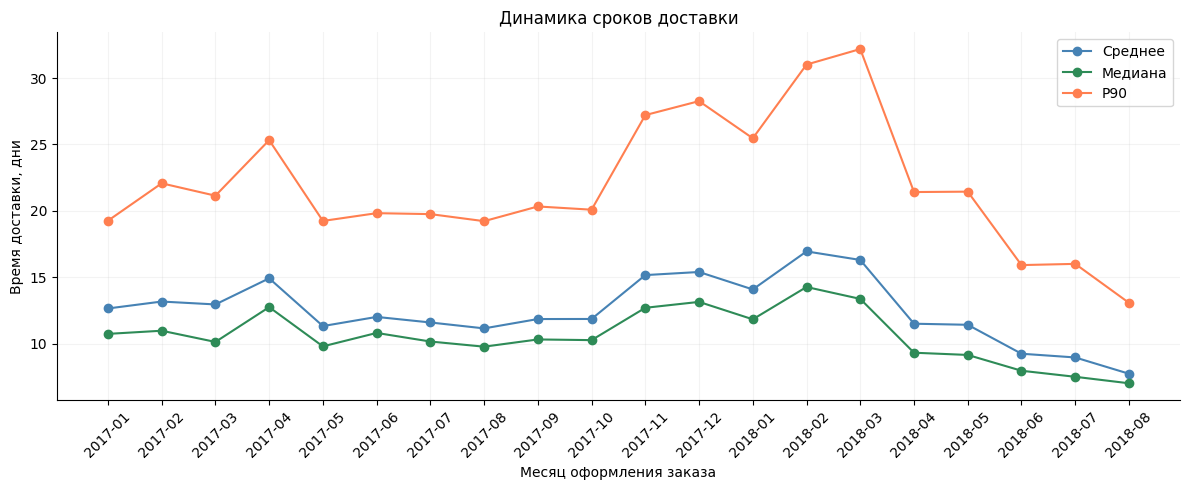

In [104]:
monthly_delivery = (order_metrics.groupby('month')['delivery_days'].agg(mean='mean',median='median',p90=lambda x: x.quantile(0.9)))
monthly_delivery = monthly_delivery[monthly_delivery.index >= '2017-01']

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_delivery.index.astype(str),monthly_delivery['mean'],marker='o', label='Среднее', color='steelblue')
ax.plot(monthly_delivery.index.astype(str),monthly_delivery['median'],marker='o', label='Медиана', color='seagreen')
ax.plot(monthly_delivery.index.astype(str),monthly_delivery['p90'],marker='o', label='P90', color='coral')

ax.set_title('Динамика сроков доставки')
ax.set_xlabel('Месяц оформления заказа')
ax.set_ylabel('Время доставки, дни')

ax.legend()
ax.grid(alpha=0.15)
ax.spines[['top', 'right']].set_visible(False)

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('images/delivery_time.png', dpi=200, bbox_inches='tight')
plt.show()

### Вывод

Анализ показал, что на протяжении большей части 2017 года среднее время доставки оставалось относительно стабильным и составляло около 11–13 дней. Однако в конце 2017 и начале 2018 года сроки доставки увеличились, особенно для заказов с наиболее долгой доставкой.

Это хорошо видно по 90-му перцентилю (P90), который в феврале–марте 2018 года достиг примерно 31–32 дней. При этом медианный срок доставки изменился не так сильно, что указывает на увеличение продолжительности доставки прежде всего у части заказов.

Таким образом, для оценки качества доставки важно учитывать не только среднее время, но и P90, поскольку он позволяет заметить проблемы с наиболее длительными доставками, которые не так заметны по средним значениям.

## Анализ бизнес-гипотез

### Гипотеза 1. Связь стоимости заказа с качеством доставки

Проверим, различаются ли сроки и доля задержек
между заказами разных ценовых категорий.

In [105]:
order_metrics['price_segment'] = pd.qcut(order_metrics['product_value'].rank(method='first'),q=4,labels=['Q1', 'Q2', 'Q3', 'Q4'])

segment_analysis = (
    order_metrics
    .groupby('price_segment', observed=True)
    .agg(
        orders=('order_id', 'count'),
        avg_order_value=('product_value', 'mean'),
        avg_delivery_days=('delivery_days', 'mean'),
        p90_delivery_days=('delivery_days',
                           lambda x: x.quantile(0.9)),
        late_rate=('is_late', 'mean')
    )
)
segment_analysis['late_rate'] *= 100
display(segment_analysis.round(2))


,orders,avg_order_value,avg_delivery_days,p90_delivery_days,late_rate
price_segment,,,,,
Q1,24118,28.51,11.45,21.37,5.92
Q2,24117,63.73,12.28,22.58,6.70
Q3,24117,114.60,12.81,23.21,6.83
Q4,24118,341.31,13.69,25.10,7.64


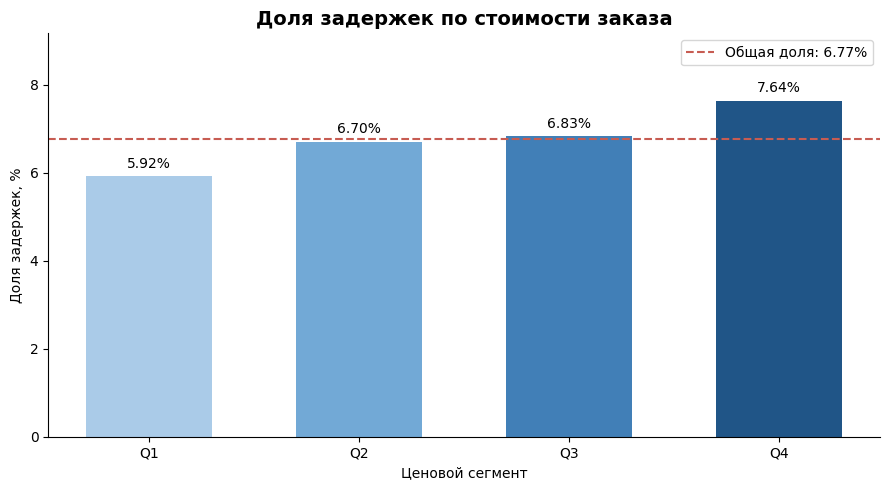

In [106]:

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(segment_analysis.index.astype(str),segment_analysis['late_rate'],color=['#AACBE8', '#72A9D6', '#417FB7', '#205587'],width=0.6)
overall_late_rate = order_metrics['is_late'].mean() * 100
ax.axhline(overall_late_rate,color='#C75C52',linestyle='--',linewidth=1.5,label=f'Общая доля: {overall_late_rate:.2f}%')

ax.bar_label(bars, fmt='%.2f%%', padding=4)

ax.set_title('Доля задержек по стоимости заказа',fontsize=14,fontweight='bold')

ax.set_xlabel('Ценовой сегмент')
ax.set_ylabel('Доля задержек, %')

ax.spines[['top', 'right']].set_visible(False)
ax.legend()
ax.set_ylim(0, max(segment_analysis['late_rate'].max(), overall_late_rate) * 1.2)

plt.tight_layout()
plt.savefig('images/price_segments.png', dpi=200, bbox_inches='tight')
plt.show()

### Вывод по гипотезе 1

Анализ показал, что с увеличением стоимости заказа растёт и среднее время доставки. В самом дешёвом сегменте (Q1) оно составляет 11,45 дня, а в самом дорогом (Q4) — 13,69 дня.

Похожая тенденция наблюдается и с задержками: их доля постепенно увеличивается с 5,92% до 7,64%. Таким образом, дорогие заказы не только доставляются дольше, но и чаще приходят позже обещанного срока.

Гипотеза о связи стоимости заказа с качеством доставки получила предварительное подтверждение. Однако нельзя утверждать, что именно высокая стоимость приводит к задержкам, поскольку на сроки доставки могут влиять и другие факторы, например расстояние до покупателя или особенности логистики.

### Гипотеза 2. Связь нагрузки с задержками

Исследуем, связаны ли месяцы с большим количеством
заказов с повышенной долей просроченных доставок.

In [107]:
monthly_performance = (order_metrics.groupby('month').agg(orders=('order_id', 'count'),late_rate=('is_late', 'mean')))
monthly_performance['late_rate'] *= 100
monthly_2017 = monthly_performance[monthly_performance.index.year == 2017].copy()
display(monthly_2017.round(2))

,orders,late_rate
month,,
2017-01,750,2.93
2017-02,1653,2.96
2017-03,2546,4.56
2017-04,2303,6.56
2017-05,3545,2.99
2017-06,3135,3.03
2017-07,3872,2.79
2017-08,4193,2.91
2017-09,4150,4.39


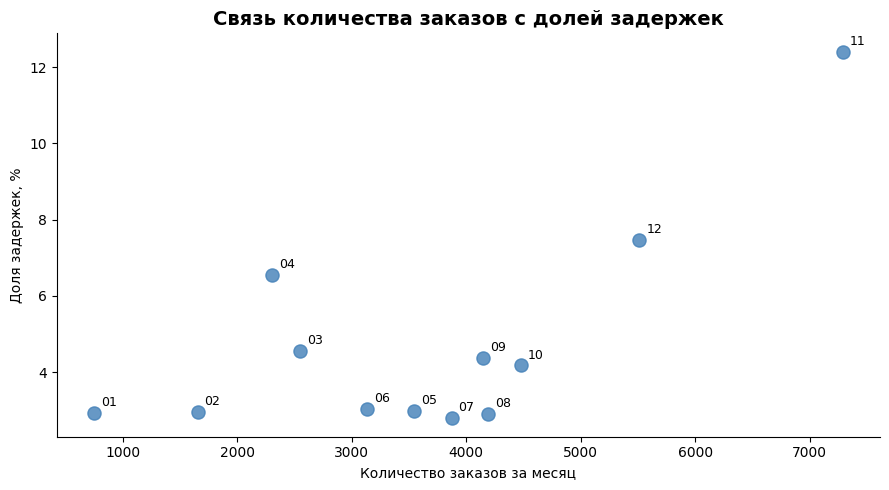

In [108]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(monthly_2017['orders'],monthly_2017['late_rate'],s=90,color='#417FB7',alpha=0.8)

for month, row in monthly_2017.iterrows():
    ax.annotate(
        str(month)[-2:],
        (row['orders'], row['late_rate']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=9
    )
ax.set_title(
    'Связь количества заказов с долей задержек',
    fontsize=14,
    fontweight='bold'
)
ax.set_xlabel('Количество заказов за месяц')
ax.set_ylabel('Доля задержек, %')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('images/order_delays.png', dpi=200, bbox_inches='tight')

plt.show()

### Вывод по гипотезе 2

Анализ показал, что увеличение количества заказов не всегда сопровождается ростом доли задержек. Например, с мая по август 2017 года количество заказов выросло с 3545 до 4193, при этом доля просроченных доставок оставалась примерно на одном уровне — около 3%.

Однако в ноябре наблюдается заметное изменение: количество заказов достигает 7288, а доля задержек увеличивается до 12,40%. Это может быть связано с сезонным ростом спроса и повышенной нагрузкой на логистику в период крупных распродаж.

Таким образом, гипотеза о связи количества заказов с долей задержек не получила однозначного подтверждения. Хотя в ноябре высокая нагрузка совпала с увеличением числа просрочек, в остальные месяцы такой устойчивой зависимости не наблюдается. На качество доставки могут влиять и другие факторы, например сезонность или особенности работы логистических служб.

## Итоговые выводы и рекомендации

### Основные результаты

В ходе исследования были проанализированы 96 470 доставленных заказов маркетплейса Olist за 2016–2018 годы. Анализ позволил выделить несколько основных закономерностей:

1. **Динамика продаж.** В течение 2017 года количество заказов и общая стоимость товаров в целом увеличивались. Наиболее заметный рост наблюдался в ноябре 2017 года.

2. **Стоимость заказов.** Средний чек составил 137,04 BRL. При этом медианный чек на протяжении большей части исследуемого периода был заметно ниже среднего, что указывает на влияние дорогих заказов на общий показатель.

3. **Качество доставки.** Средний срок доставки составил 12,56 дня, а 90% заказов доставлялись в течение 23,1 дня. Доля доставок с опозданием составила 6,77%.

4. **Связь стоимости заказа и доставки.** Анализ показал, что с увеличением стоимости заказа растут среднее время доставки и доля задержек. В самом дорогом сегменте доля просрочек составила 7,64% против 5,92% в самом дешёвом.

5. **Влияние нагрузки на доставку.** Устойчивой зависимости между количеством заказов и долей задержек обнаружено не было. Однако в ноябре 2017 года одновременно наблюдались максимальное количество заказов и высокая доля просрочек — 12,40%.

### Рекомендации для бизнеса

На основе полученных результатов можно предложить следующие рекомендации:

1. **Усилить контроль доставки дорогих заказов.** В этом сегменте наблюдаются более длительные сроки доставки и повышенная доля задержек. Стоит дополнительно изучить причины этих различий и при необходимости пересмотреть логистические процессы.

2. **Учитывать сезонные изменения нагрузки.** Резкий рост количества заказов и задержек в ноябре 2017 года показывает, что периоды повышенного спроса требуют отдельного внимания. Можно заранее отслеживать нагрузку и проверять готовность логистических служб к пиковым периодам.

3. **Использовать несколько показателей качества доставки.** Помимо среднего срока, стоит регулярно отслеживать медиану, P90 и долю просрочек. Это позволит своевременно замечать проблемы, которые не всегда отражаются в среднем значении.

### Ограничения исследования

Анализ проводился только для доставленных заказов с известной датой получения. Поэтому полученные результаты не отражают ситуацию с отменёнными и недоставленными заказами.

Кроме того, выявленные закономерности показывают связь между показателями, но не доказывают причинно-следственную зависимость. Для более точного определения причин задержек потребовалось бы дополнительно изучить географию заказов, особенности продавцов и логистические процессы.